# EN3160 ASSIGNMENT 02
## FITTING AND ALIGNMENT

**M.R.A.Hakam**  **230224V**

[github.com/hakammra](https://github.com/hakammra)

### INTRODUCTION

This report studies blob detection, fitting models to noisy points, image compositing and PCB alignment. The methods follow the supplied notes and examples, with code and results shown for each question

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

ROOT = Path.cwd()
cv.setNumThreads(2)


### QUESTION 1  BLOB DETECTION

The LoG kernel follows the supplied blob notebook. The sunflower image is reduced to 360 by 360 pixels. Sigma values are 1 to 12 with step 0.5 and the radius is sqrt(2) times sigma

Positive responses find dark flower centres. Local maxima are compared across image position and scale. A response limit of 0.22, a yellow ring check of at least 35% and duplicate removal give the final circles. Boundary scales and clipped circles are excluded

In [2]:
def normalized_log_kernel(sigma):
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError('Sigma must be positive and finite')
    half_width = int(np.ceil(3 * sigma))
    coordinates = np.arange(-half_width, half_width + 1, dtype=np.float64)
    x, y = np.meshgrid(coordinates, coordinates)
    squared_distance = x ** 2 + y ** 2
    kernel = (squared_distance / sigma ** 2 - 2) * np.exp(-squared_distance / (2 * sigma ** 2)) / (2 * np.pi * sigma ** 2)
    return kernel.astype(np.float32)

def build_scale_space(image, sigmas):
    image = np.asarray(image, dtype=np.float32)
    if image.ndim != 2:
        raise ValueError('Scale space input must be a grayscale image')
    if len(sigmas) == 0:
        raise ValueError('At least one sigma is required')
    responses = [cv.filter2D(image, cv.CV_32F, normalized_log_kernel(sigma)) for sigma in sigmas]
    return np.stack(responses, axis=-1)

def scale_space_extrema(scale_space, sigmas, response_threshold):
    if len(sigmas) < 3 or scale_space.shape[2] != len(sigmas):
        raise ValueError('Scale space needs at least three matching sigma values')
    if response_threshold <= 0:
        raise ValueError('The response threshold must be positive')
    local_maxima = maximum_filter(scale_space, size=3, mode='nearest')
    maxima = (scale_space == local_maxima) & (scale_space >= response_threshold)
    maxima[:, :, 0] = False
    maxima[:, :, -1] = False
    coordinates = np.argwhere(maxima)
    return sorted(coordinates, key=lambda point: float(scale_space[tuple(point)]), reverse=True)

def yellow_ring_fraction(yellow_mask, x, y, radius, outer_radius_factor):
    height, width = yellow_mask.shape
    half_width = int(np.ceil(outer_radius_factor * radius))
    x0, x1 = (max(0, x - half_width), min(width, x + half_width + 1))
    y0, y1 = (max(0, y - half_width), min(height, y + half_width + 1))
    rows, columns = np.ogrid[y0:y1, x0:x1]
    squared_distance = (columns - x) ** 2 + (rows - y) ** 2
    ring = (squared_distance > radius ** 2) & (squared_distance <= (outer_radius_factor * radius) ** 2)
    return float(yellow_mask[y0:y1, x0:x1][ring].mean())

sunflower_image = cv.imread(str(ROOT / 'images/the_berry_farms_sunflower_field.jpeg'), cv.IMREAD_REDUCED_COLOR_4)
if sunflower_image is None:
    raise FileNotFoundError('The sunflower image is required')
sigma_values = np.arange(1, 12.5, 0.5)
print(f'Image size: {sunflower_image.shape[1]} by {sunflower_image.shape[0]} pixels')
print(f'Sigma range: {sigma_values[0]:g} to {sigma_values[-1]:g} with step 0.5')
print(f'Number of scales: {len(sigma_values)}')


Image size: 360 by 360 pixels
Sigma range: 1 to 12 with step 0.5
Number of scales: 23


Detected centres: 65
Circle     x     y    Radius    Sigma
     1   282   338     10.61      7.5
     2   106   255      8.49        6
     3   179   327      8.49        6
     4   178   261      7.78      5.5
     5   161   290      6.36      4.5


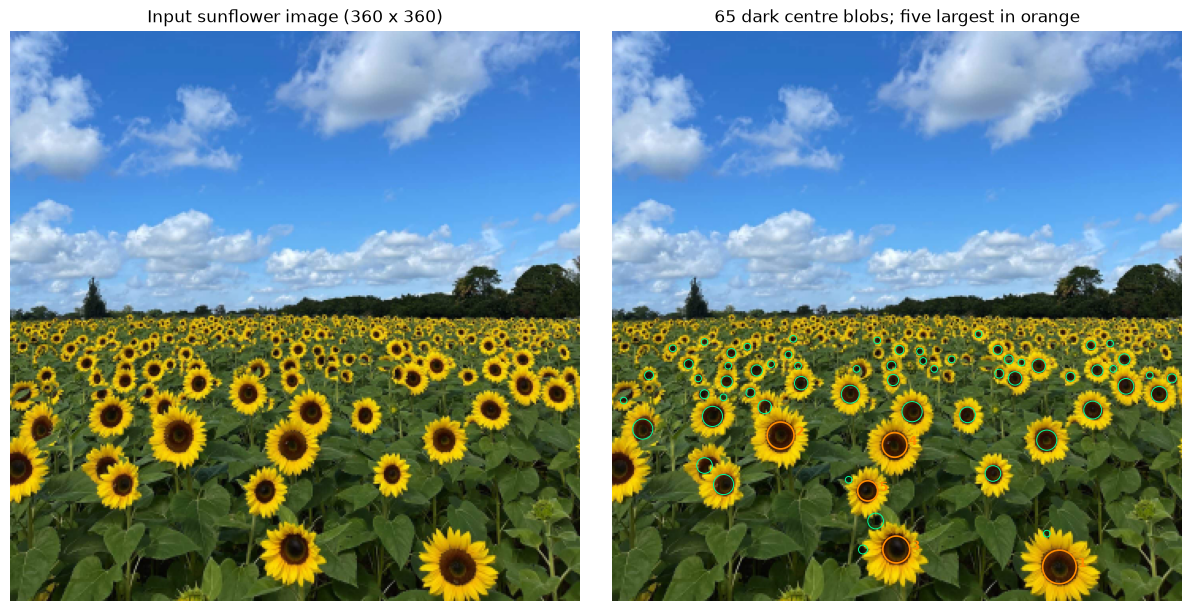

In [3]:
def detect_sunflowers():
    image_path = ROOT / 'images' / 'the_berry_farms_sunflower_field.jpeg'
    image = cv.imread(str(image_path), cv.IMREAD_REDUCED_COLOR_4)
    if image is None:
        raise FileNotFoundError(f'Cannot load image: {image_path.name}')
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    sigmas = np.arange(1.0, 12.5, 0.5)
    response_threshold = 0.22
    minimum_yellow_fraction = 0.35
    outer_radius_factor = 2.2
    minimum_separation_factor = 0.6
    hsv_lower = [15, 100, 120]
    hsv_upper = [38, 255, 255]
    scale_space = build_scale_space(gray, sigmas)
    candidates = scale_space_extrema(scale_space, sigmas, response_threshold)
    hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
    yellow_mask = cv.inRange(hsv, np.array(hsv_lower), np.array(hsv_upper)) > 0
    height, width = gray.shape
    circles = []
    for row, column, scale_index in candidates:
        x, y = (int(column), int(row))
        sigma = float(sigmas[scale_index])
        radius = float(np.sqrt(2) * sigma)
        if x < radius or y < radius or x + radius >= width or (y + radius >= height):
            continue
        yellow_fraction = yellow_ring_fraction(yellow_mask, x, y, radius, outer_radius_factor)
        if yellow_fraction < minimum_yellow_fraction:
            continue
        if any((np.hypot(
            x - circle['x'],
            y - circle['y'],
        ) < minimum_separation_factor * (radius + circle['radius']) for circle in circles)):
            continue
        circles.append({
            'x': x,
            'y': y,
            'radius': radius,
            'sigma': sigma,
            'response': float(scale_space[row, column, scale_index]),
            'yellow_ring_fraction': yellow_fraction,
        })
    circles.sort(key=lambda circle: (-circle['radius'], -circle['response']))
    if not circles:
        raise RuntimeError('No sunflower blobs passed the detection thresholds')
    rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
    axes[0].imshow(rgb)
    axes[0].set_title('Input sunflower image (360 x 360)')
    axes[1].imshow(rgb)
    axes[1].set_title(f'{len(circles)} dark centre blobs; five largest in orange')
    for index, circle in enumerate(circles):
        color = '#ff8c00' if index < 5 else '#00ff99'
        axes[1].add_patch(plt.Circle(
            (circle['x'], circle['y']),
            circle['radius'],
            fill=False,
            color=color,
            linewidth=1.2 if index < 5 else 0.7,
        ))
        if index < 5:
            axes[1].text(
                circle['x'] + circle['radius'] + 1,
                circle['y'],
                str(index + 1),
                color=color,
                fontsize=9,
                weight='bold',
            )
    for axis in axes:
        axis.set_axis_off()
    plt.show()
    return circles

sunflower_circles = detect_sunflowers()
print(f'Detected centres: {len(sunflower_circles)}')
print('Circle     x     y    Radius    Sigma')
for index, circle in enumerate(sunflower_circles[:5], 1):
    print(f"{index:6d} {circle['x']:5d} {circle['y']:5d} {circle['radius']:9.2f} {circle['sigma']:8g}")


**RESULTS AND DISCUSSION**

There are 65 detected centres and the five largest are marked in orange. Coordinates and radii use the reduced image. The circles describe dark centres and exclude the petals

Clear foreground centres are found well, while some small distant flowers are missed. Nearby centres can merge during duplicate removal

### QUESTION 2  LINE AND CIRCLE FITTING

The supplied point generator gives 50 noisy line points and 50 noisy circle points using seed 0. Both RANSAC loops are written directly

Two points form a line sample and three points form a circle sample. The line uses perpendicular distance with a unit normal, threshold 1.4 and minimum consensus 40. The circle uses radial distance, threshold 1.25 and minimum consensus 30. Both use 500 samples

The larger consensus wins, with mean squared error breaking ties. The line is refined by total least squares and the circle by minimizing squared radial errors

The error thresholds are about twice the expected noise levels. This allows small measurement errors while rejecting points far from each model

Generated points: 100
Circle points: 50
Line points: 50


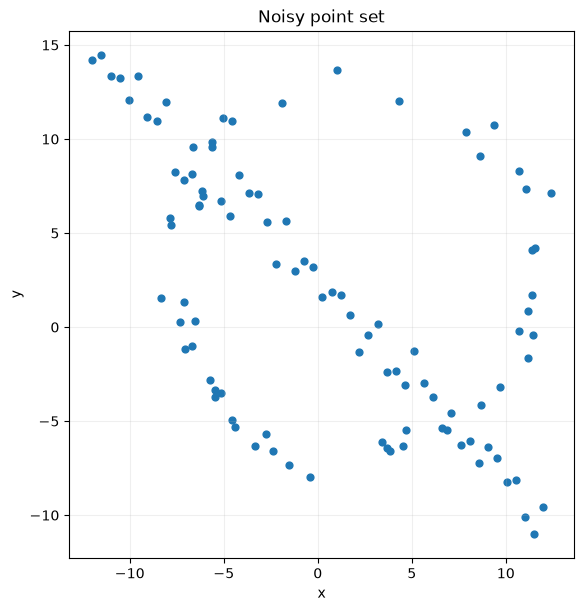

In [4]:
def generate_points(seed=0):
    rng = np.random.RandomState(seed)
    count = 50
    angles = rng.uniform(0, 2 * np.pi, count)
    radii = 10 + 10 / 16 * rng.randn(count)
    circle = np.column_stack((2 + radii * np.cos(angles), 3 + radii * np.sin(angles)))
    x = np.linspace(-12, 12, count)
    line = np.column_stack((x, -x + 2 + rng.randn(count)))
    return np.vstack((circle, line))

points = generate_points(seed=0)
print(f'Generated points: {len(points)}')
print('Circle points: 50')
print('Line points: 50')
fig, axis = plt.subplots(figsize=(6, 6), layout='constrained')
axis.scatter(*points.T, s=24, color='tab:blue')
axis.set(xlabel='x', ylabel='y', title='Noisy point set')
axis.set_aspect('equal')
axis.grid(alpha=0.2)
plt.show()


In [5]:
def line_from_points(points):
    direction = points[1] - points[0]
    length = np.linalg.norm(direction)
    if length < 1e-10:
        raise ValueError('The two points must be different')
    normal = np.array([direction[1], -direction[0]]) / length
    model = np.append(normal, normal @ points[0])
    return -model if model[2] < 0 else model

def line_errors(points, model):
    return np.abs(points @ model[:2] - model[2])

def fit_line(points):
    center = points.mean(axis=0)
    _, _, vectors = np.linalg.svd(points - center, full_matrices=False)
    normal = vectors[-1]
    model = np.append(normal, normal @ center)
    return -model if model[2] < 0 else model

def ransac_line(points, threshold=1.4, minimum_inliers=40, iterations=500, seed=1):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) < 2:
        raise ValueError('Provide at least two points with x and y coordinates')
    if not np.isfinite(points).all():
        raise ValueError('Point coordinates must be finite')
    if threshold <= 0 or not 2 <= minimum_inliers <= len(points) or iterations < 1:
        raise ValueError('Invalid RANSAC parameters')
    rng = np.random.default_rng(seed)
    best = None
    best_score = (-1, -np.inf)
    for iteration in range(iterations):
        sample = rng.choice(len(points), 2, replace=False)
        try:
            sample_model = line_from_points(points[sample])
        except ValueError:
            continue
        sample_mask = line_errors(points, sample_model) <= threshold
        if sample_mask.sum() < minimum_inliers:
            continue
        inliers = sample_mask.copy()
        for _ in range(10):
            model = fit_line(points[inliers])
            updated = line_errors(points, model) <= threshold
            if updated.sum() < minimum_inliers or np.array_equal(updated, inliers):
                break
            inliers = updated
        errors = line_errors(points, model)
        inliers = errors <= threshold
        count = int(inliers.sum())
        if count < minimum_inliers:
            continue
        mean_squared_error = float(np.mean(errors[inliers] ** 2))
        score = (count, -mean_squared_error)
        if score > best_score:
            best_score = score
            best = {
                'model': model,
                'sample_model': sample_model,
                'sample_indices': sample,
                'sample_inlier_indices': np.flatnonzero(sample_mask),
                'inlier_indices': np.flatnonzero(inliers),
                'inlier_count': count,
                'inlier_rmse': float(np.sqrt(mean_squared_error)),
                'winning_iteration': iteration + 1,
                'threshold': threshold,
                'minimum_inliers': minimum_inliers,
                'iterations': iterations,
                'seed': seed,
            }
    if best is None:
        raise RuntimeError('No line reached the required consensus')
    return best

line = ransac_line(points)
print('Line (a, b, d):', np.round(line['model'], 4))
print(f"Normal length: {np.linalg.norm(line['model'][:2]):.4f}")
print(f"Line inliers: {line['inlier_count']} of {len(points)}")
print(f"Line inlier RMSE: {line['inlier_rmse']:.4f}")


Line (a, b, d): [0.721  0.693  1.5724]
Normal length: 1.0000
Line inliers: 54 of 100
Line inlier RMSE: 0.6706


In [6]:
def circle_from_points(points):
    offsets = points[1:] - points[0]
    matrix = 2 * offsets
    if np.linalg.cond(matrix) > 100000000.0:
        raise ValueError('The circle sample is too close to a straight line')
    right = np.sum(offsets ** 2, axis=1)
    relative_center = np.linalg.solve(matrix, right)
    center = points[0] + relative_center
    radius = np.linalg.norm(relative_center)
    model = np.append(center, radius)
    if not np.isfinite(model).all() or radius < 1e-10:
        raise ValueError('The circle sample is invalid')
    return model

def circle_errors(points, model):
    return np.abs(np.linalg.norm(points - model[:2], axis=1) - model[2])

def fit_circle(points, initial_model):

    def objective(model):
        residuals = np.linalg.norm(points - model[:2], axis=1) - model[2]
        return float(residuals @ residuals)
    result = minimize(
        objective,
        initial_model,
        method='L-BFGS-B',
        bounds=[(None, None), (None, None), (1e-08, None)],
        options={'ftol': 1e-12, 'gtol': 1e-07, 'maxiter': 300},
    )
    if not result.success or not np.isfinite(result.x).all():
        raise RuntimeError('Circle refinement did not converge')
    return result.x

def ransac_circle(points, threshold=1.25, minimum_inliers=30, iterations=500, seed=2):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) < 3:
        raise ValueError('Provide at least three points with x and y coordinates')
    if not np.isfinite(points).all():
        raise ValueError('Point coordinates must be finite')
    if threshold <= 0 or not 3 <= minimum_inliers <= len(points) or iterations < 1:
        raise ValueError('Invalid RANSAC parameters')
    rng = np.random.default_rng(seed)
    best = None
    best_score = (-1, -np.inf)
    for iteration in range(iterations):
        sample = rng.choice(len(points), 3, replace=False)
        try:
            sample_model = circle_from_points(points[sample])
        except (ValueError, np.linalg.LinAlgError):
            continue
        sample_mask = circle_errors(points, sample_model) <= threshold
        if sample_mask.sum() < minimum_inliers:
            continue
        inliers = sample_mask.copy()
        model = sample_model.copy()
        try:
            for _ in range(10):
                model = fit_circle(points[inliers], model)
                updated = circle_errors(points, model) <= threshold
                if updated.sum() < minimum_inliers or np.array_equal(updated, inliers):
                    break
                inliers = updated
        except RuntimeError:
            continue
        errors = circle_errors(points, model)
        inliers = errors <= threshold
        count = int(inliers.sum())
        if count < minimum_inliers:
            continue
        mean_squared_error = float(np.mean(errors[inliers] ** 2))
        score = (count, -mean_squared_error)
        if score > best_score:
            best_score = score
            best = {
                'model': model,
                'sample_model': sample_model,
                'sample_indices': sample,
                'sample_inlier_indices': np.flatnonzero(sample_mask),
                'inlier_indices': np.flatnonzero(inliers),
                'inlier_count': count,
                'inlier_rmse': float(np.sqrt(mean_squared_error)),
                'winning_iteration': iteration + 1,
                'threshold': threshold,
                'minimum_inliers': minimum_inliers,
                'iterations': iterations,
                'seed': seed,
            }
    if best is None:
        raise RuntimeError('No circle reached the required consensus')
    return best

remaining = np.setdiff1d(np.arange(len(points)), line['inlier_indices'])
circle = ransac_circle(points[remaining])
for field in ['sample_indices', 'sample_inlier_indices', 'inlier_indices']:
    circle[field] = remaining[circle[field]]
print(f'Points remaining after removing the line: {len(remaining)}')
print('Circle (x, y, radius):', np.round(circle['model'], 4))
print(f"Circle inliers: {circle['inlier_count']} of {len(remaining)}")
print(f"Circle inlier RMSE: {circle['inlier_rmse']:.4f}")


Points remaining after removing the line: 46
Circle (x, y, radius): [1.8982 3.0101 9.8314]
Circle inliers: 44 of 46
Circle inlier RMSE: 0.5311


Order                 Line inliers    Circle inliers
Line then circle                54                44
Circle then line                41                57


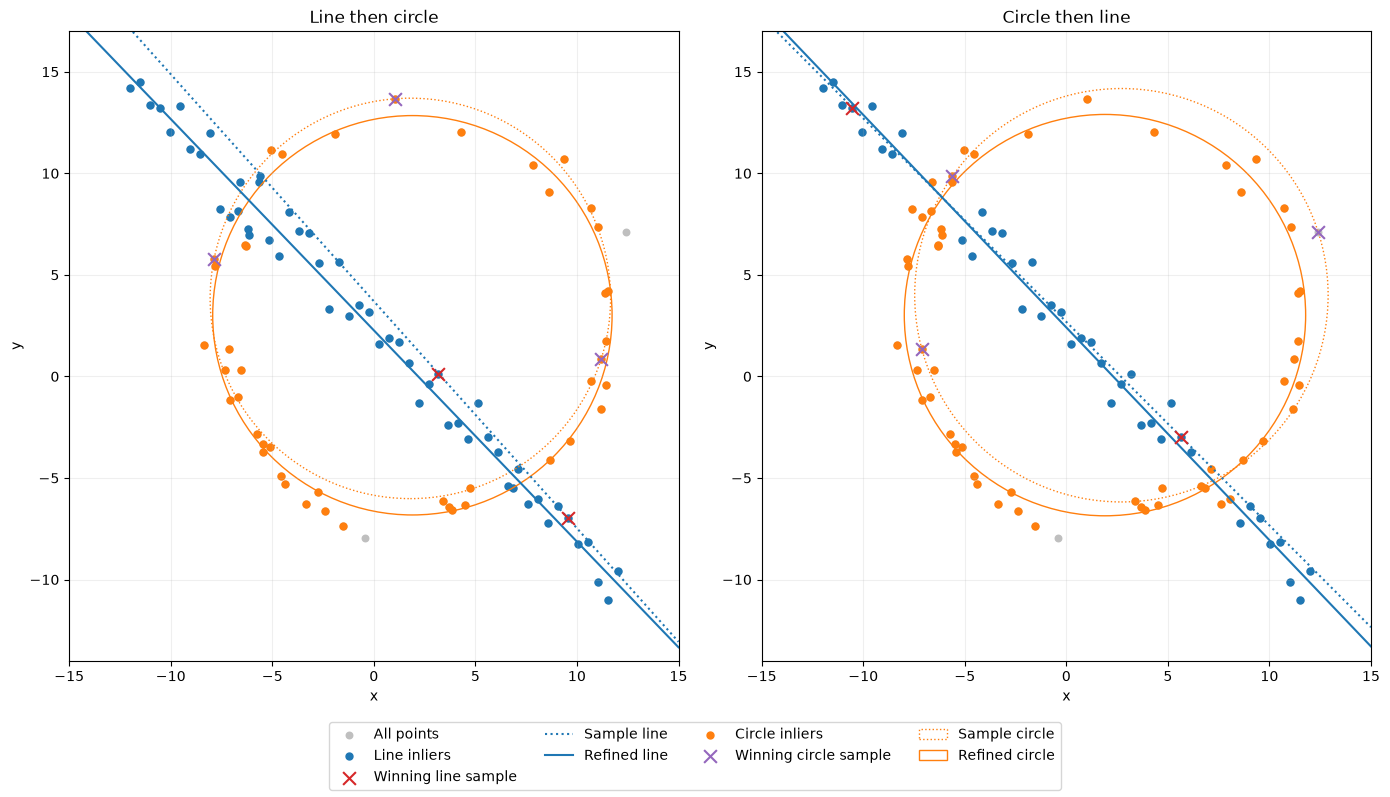

In [7]:
def fit_circle_then_line(points):
    circle = ransac_circle(points)
    circle['input_point_count'] = len(points)
    remaining = np.setdiff1d(np.arange(len(points)), circle['inlier_indices'])
    line = None
    failure = None
    if len(remaining) < 40:
        failure = 'Too few points remain for the minimum line consensus of 40'
    else:
        try:
            line = ransac_line(points[remaining])
        except RuntimeError as error:
            failure = str(error)
    if line is not None:
        for name in ('sample_indices', 'sample_inlier_indices', 'inlier_indices'):
            line[name] = remaining[line[name]]
        line['input_point_count'] = len(remaining)
        line['remaining_point_indices'] = remaining
    return {'circle': circle, 'line': line, 'remaining_point_indices': remaining, 'line_failure': failure}

def plot_line(axis, model, label, color, linestyle='solid'):
    a, b, d = model
    if abs(b) < 1e-10:
        axis.axvline(d / a, label=label, color=color, linestyle=linestyle)
    else:
        x = np.array([-15, 15])
        axis.plot(x, (d - a * x) / b, label=label, color=color, linestyle=linestyle)

def plot_fitting_order(axis, points, line, circle, title):
    axis.scatter(*points.T, s=22, color='0.75', label='All points')
    for result, label, color, sample_color in (
        (line, 'Line', 'tab:blue', 'tab:red'),
        (circle, 'Circle', 'tab:orange', 'tab:purple'),
    ):
        if result is None:
            continue
        axis.scatter(*points[result['inlier_indices']].T, s=25, color=color, label=f'{label} inliers')
        axis.scatter(
            *points[result['sample_indices']].T,
            s=85,
            marker='x',
            color=sample_color,
            label=f'Winning {label.lower()} sample',
            zorder=5,
        )
        for model_name, model_label, style in (
            ('sample_model', f'Sample {label.lower()}', 'dotted'),
            ('model', f'Refined {label.lower()}', 'solid'),
        ):
            model = result[model_name]
            if label == 'Line':
                plot_line(axis, model, model_label, color, style)
            else:
                axis.add_patch(plt.Circle(
                    model[:2],
                    model[2],
                    fill=False,
                    label=model_label,
                    color=color,
                    linestyle=style,
                ))
    if line is None:
        axis.text(0.5, 0.04, 'No line consensus', ha='center', transform=axis.transAxes)
    axis.set(xlim=(-15, 15), ylim=(-14, 17), xlabel='x', ylabel='y', title=title)
    axis.set_aspect('equal')
    axis.grid(alpha=0.2)

reverse = fit_circle_then_line(points)
print('Order                 Line inliers    Circle inliers')
print(f"Line then circle      {line['inlier_count']:12d}    {circle['inlier_count']:14d}")
if reverse['line'] is None:
    print('Circle then line:', reverse['line_failure'])
else:
    print(f"Circle then line      {reverse['line']['inlier_count']:12d}    {reverse['circle']['inlier_count']:14d}")
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
plot_fitting_order(axes[0], points, line, circle, 'Line then circle')
plot_fitting_order(axes[1], points, reverse['line'], reverse['circle'], 'Circle then line')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=10)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()


**RESULTS AND DISCUSSION**

With the line fitted first, all 50 generated line points and four nearby circle points enter its consensus. Removing this consensus leaves 46 points and the circle keeps 44. The estimated centre is (1.90, 3.01) and radius is 9.83, close to the true centre (2, 3) and radius 10

Fitting the circle first keeps 57 points, including nine generated line points near its boundary. The line then keeps 41 of the 43 remaining points. The first fit changes the points available to the second fit and can leave too few points for it in other samples

### QUESTION 3  FOUR POINT IMAGE COMPOSITING

Four corners on a flat surface are selected in the order top left, top right, bottom right and bottom left. A homography maps the overlay corners to these points, then the warped image is blended onto the surface

The chosen pairs place a fruit image on a box and a butterfly image on a wall. Opacity is 0.8 for the box and 0.85 for the wall. The saved coordinates below reproduce the results. Set select_new_points to True to click four new points in a separate window

The box and wall provide clear flat surfaces for placing the overlays

In [8]:
def validate_corners(corners, shape):
    corners = np.asarray(corners, dtype=np.float32)
    if corners.shape != (4, 2) or not np.isfinite(corners).all():
        raise ValueError('Provide four finite image coordinates')
    height, width = shape[:2]
    if np.any(corners < 0) or np.any(corners[:, 0] >= width) or np.any(corners[:, 1] >= height):
        raise ValueError('The corners must be inside the background image')
    if not cv.isContourConvex(corners.reshape(-1, 1, 2)) or cv.contourArea(corners) < 1:
        raise ValueError('Select the corners around a convex region')
    return corners

def select_corners(image):
    height, width = image.shape[:2]
    scale = min(1000 / width, 700 / height, 1)
    preview = cv.resize(image, None, fx=scale, fy=scale)
    points = []
    title = 'Top left, top right, bottom right, bottom left   Enter to save   R to reset'

    def redraw():
        frame = preview.copy()
        for index, point in enumerate(points, 1):
            position = tuple(np.round(np.array(point) * scale).astype(int))
            cv.circle(frame, position, 5, (0, 255, 255), -1)
            cv.putText(frame, str(index), position, cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        if len(points) == 4:
            contour = np.round(np.array(points) * scale).astype(np.int32)
            cv.polylines(frame, [contour], True, (0, 255, 255), 2)
        cv.imshow(title, frame)

    def on_click(event, x, y, flags, data):
        if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
            points.append([x / scale, y / scale])
            redraw()
    cv.namedWindow(title, cv.WINDOW_AUTOSIZE)
    cv.setMouseCallback(title, on_click)
    redraw()
    try:
        while True:
            key = cv.waitKey(20) & 255
            if key == 27 or cv.getWindowProperty(title, cv.WND_PROP_VISIBLE) < 1:
                raise RuntimeError('Point selection was cancelled')
            if key in (ord('r'), ord('R')):
                points.clear()
                redraw()
            if key in (10, 13) and len(points) == 4:
                return validate_corners(points, image.shape)
    finally:
        cv.destroyAllWindows()

examples = [
    {
        'background': 'images/compositing/box_in_scene.png',
        'overlay': 'images/compositing/fruits.jpg',
        'corners': [[121, 177], [228, 186], [217, 266], [103, 252]],
        'opacity': 0.8,
        'title': 'Fruit on box',
    },
    {
        'background': 'images/compositing/graf1.png',
        'overlay': 'images/compositing/butterfly.jpg',
        'corners': [[80, 60], [697, 92], [671, 460], [112, 487]],
        'opacity': 0.85,
        'title': 'Butterfly on wall',
    },
]
select_new_points = False

selected_examples = []
for example in examples:
    background = cv.imread(str(ROOT / example['background']))
    overlay = cv.imread(str(ROOT / example['overlay']), cv.IMREAD_UNCHANGED)
    if background is None or overlay is None:
        raise FileNotFoundError('The background and overlay images are required')
    corners = select_corners(background) if select_new_points else example['corners']
    corners = validate_corners(corners, background.shape)
    selected_examples.append((background, overlay, corners))
    print(example['title'])
    print('Corners:', np.round(corners, 1).tolist())
    print(f"Opacity: {example['opacity']:g}")


Fruit on box
Corners: [[121.0, 177.0], [228.0, 186.0], [217.0, 266.0], [103.0, 252.0]]
Opacity: 0.8
Butterfly on wall
Corners: [[80.0, 60.0], [697.0, 92.0], [671.0, 460.0], [112.0, 487.0]]
Opacity: 0.85


Fruit on box
Homography:
[[ 1.867e-01 -5.180e-02  1.210e+02]
 [-9.000e-04  1.217e-01  1.770e+02]
 [-1.000e-04 -1.000e-04  1.000e+00]]
Butterfly on wall
Homography:
[[1.4928e+00 1.2530e-01 8.0000e+01]
 [9.6600e-02 1.3559e+00 6.0000e+01]
 [3.0000e-04 3.0000e-04 1.0000e+00]]


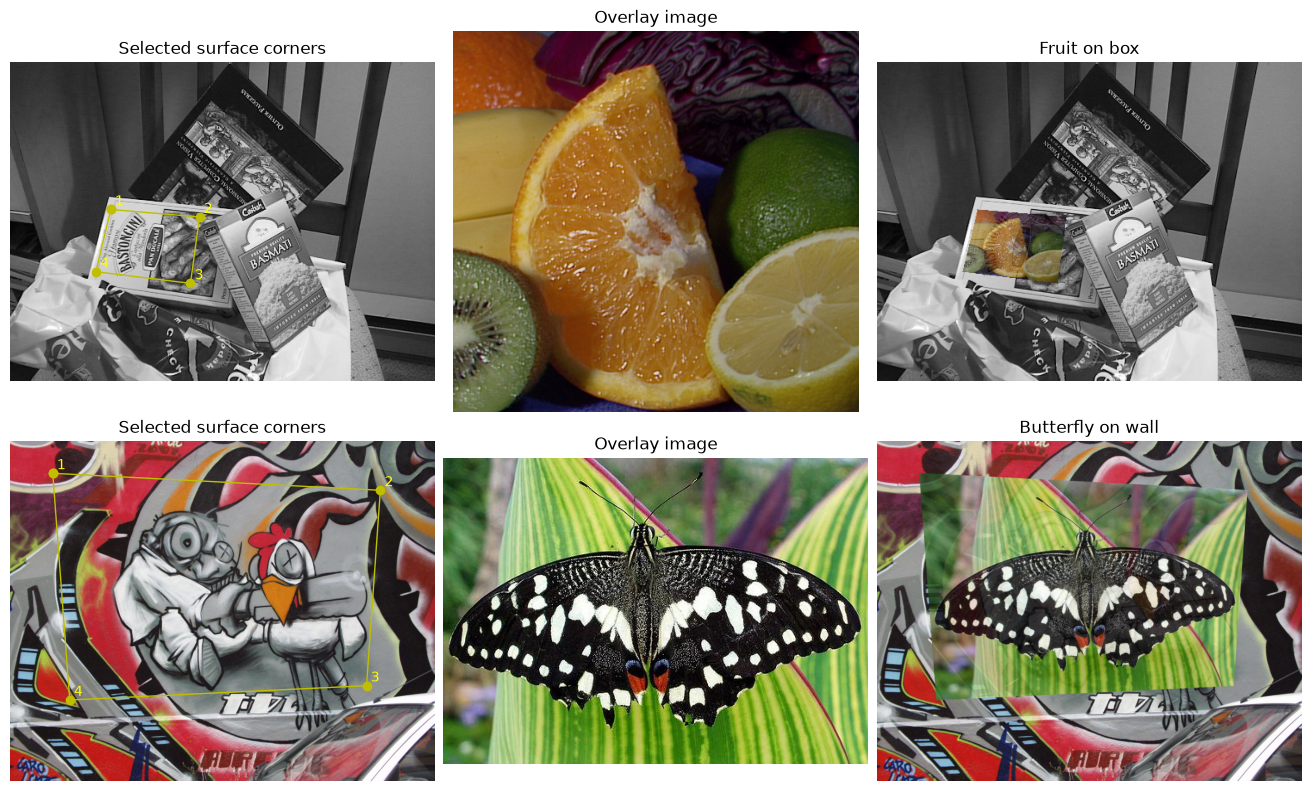

In [9]:
def composite_overlay(background, overlay, corners, opacity=0.75):
    corners = validate_corners(corners, background.shape)
    if not 0 <= opacity <= 1:
        raise ValueError('Opacity must be between zero and one')
    if overlay.ndim != 3 or overlay.shape[2] not in (3, 4):
        raise ValueError('The overlay must be a colour image')
    height, width = overlay.shape[:2]
    source = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
    homography = cv.getPerspectiveTransform(source, corners)
    if not np.isfinite(homography).all() or np.linalg.cond(homography) > 1000000000000.0:
        raise ValueError('The selected corners give an unstable homography')
    alpha = overlay[
        :,
        :,
        3,
    ].astype(np.float32) / 255 if overlay.shape[2] == 4 else np.ones((height, width), np.float32)
    colours = overlay[:, :, :3].astype(np.float32) * alpha[:, :, None]
    size = (background.shape[1], background.shape[0])
    warped = cv.warpPerspective(colours, homography, size, flags=cv.INTER_LINEAR)
    coverage = cv.warpPerspective(alpha, homography, size, flags=cv.INTER_LINEAR)
    result = background.astype(np.float32) * (1 - opacity * coverage[:, :, None]) + opacity * warped
    return (np.clip(np.round(result), 0, 255).astype(np.uint8), homography, coverage)

composites = []
fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout='constrained')
for row, (example, selected) in enumerate(zip(examples, selected_examples)):
    background, overlay, corners = selected
    composite, homography, coverage = composite_overlay(background, overlay, corners, example['opacity'])
    composites.append((composite, homography, coverage))
    print(example['title'])
    print('Homography:')
    print(np.round(homography, 4))
    axes[row, 0].imshow(cv.cvtColor(background, cv.COLOR_BGR2RGB))
    closed = np.vstack([corners, corners[0]])
    axes[row, 0].plot(closed[:, 0], closed[:, 1], 'yo-', linewidth=1)
    for index, point in enumerate(corners, 1):
        axes[row, 0].annotate(str(index), point, xytext=(3, 3), textcoords='offset points', color='yellow')
    conversion = cv.COLOR_BGRA2RGBA if overlay.shape[2] == 4 else cv.COLOR_BGR2RGB
    axes[row, 1].imshow(cv.cvtColor(overlay, conversion))
    axes[row, 2].imshow(cv.cvtColor(composite, cv.COLOR_BGR2RGB))
    axes[row, 0].set_title('Selected surface corners')
    axes[row, 1].set_title('Overlay image')
    axes[row, 2].set_title(example['title'])
for axis in axes.flat:
    axis.axis('off')
plt.show()


**RESULTS AND DISCUSSION**

Both overlays follow the selected surface. Blending keeps some surface texture visible and changes only pixels inside the warped overlay mask

The selected corners control the perspective, so the result depends on choosing a suitable flat region

### QUESTION 4  PCB ALIGNMENT

SIFT and the ratio test follow the supplied blob example, using BFMatcher with L2 distance. A ratio limit of 0.8 and mutual matches reject ambiguous pairs. RANSAC estimates each homography with a five pixel threshold

Features are detected with the longer side reduced to 1000 pixels and are mapped back to the original coordinates. Each view shows up to 80 inlier matches to AECC1

In [10]:
def detect_sift(image, sift, maximum_side=1000):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    scale = min(maximum_side / max(gray.shape), 1)
    small = cv.resize(gray, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
    keypoints, descriptors = sift.detectAndCompute(small, None)
    sx, sy = (small.shape[1] / gray.shape[1], small.shape[0] / gray.shape[0])
    keypoints = [cv.KeyPoint(
        point.pt[0] / sx,
        point.pt[1] / sy,
        point.size / np.sqrt(sx * sy),
        point.angle,
        point.response,
        point.octave,
        point.class_id,
    ) for point in keypoints]
    return (keypoints, descriptors, gray.shape)

pcb_names = ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']
reference = cv.imread(str(ROOT / 'images/pcbs/AECC1.jpg'))
if reference is None:
    raise FileNotFoundError('AECC1.jpg is required as the reference image')
sift = cv.SIFT_create(nfeatures=5000)
reference_features = detect_sift(reference, sift)
print('Reference image: AECC1.jpg')
print(f'Reference SIFT keypoints: {len(reference_features[0])}')
print(f'PCB images to align: {len(pcb_names)}')


Reference image: AECC1.jpg
Reference SIFT keypoints: 3539
PCB images to align: 5


Image       Matches    Inliers    Inlier RMSE
AAAA1            76         33         2.5042
ADAD1           236        175         1.2612
AECC2          1987       1881         0.7145
AECC3          2156       2050         0.6140
AECC4          1976       1885         0.7335


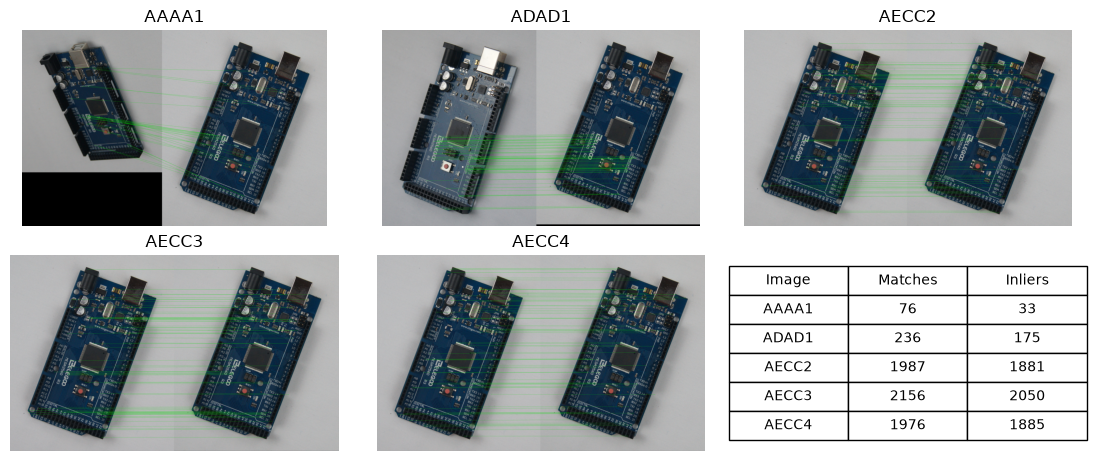

In [11]:
def estimate_pcb_homography(image, reference_features, sift, ratio=0.8, threshold=5.0):
    keypoints, descriptors, _ = detect_sift(image, sift)
    reference_keypoints, reference_descriptors, reference_shape = reference_features
    if descriptors is None or reference_descriptors is None:
        raise RuntimeError('SIFT descriptors could not be found')
    matcher = cv.BFMatcher(cv.NORM_L2)
    neighbours = matcher.knnMatch(descriptors, reference_descriptors, k=2)
    reverse = {match.queryIdx: match.trainIdx for match in matcher.match(reference_descriptors, descriptors)}
    matches = [pair[0] for pair in neighbours if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance and (reverse[pair[0].trainIdx] == pair[0].queryIdx)]
    if len(matches) < 4:
        raise RuntimeError('At least four reliable matches are required')
    source = np.float32([keypoints[match.queryIdx].pt for match in matches])
    destination = np.float32([reference_keypoints[match.trainIdx].pt for match in matches])
    cv.setRNGSeed(0)
    homography, mask = cv.findHomography(
        source,
        destination,
        cv.RANSAC,
        threshold,
        maxIters=5000,
        confidence=0.995,
    )
    if homography is None or mask is None or (not np.isfinite(homography).all()) or (np.linalg.matrix_rank(homography) != 3):
        raise RuntimeError('A valid PCB homography could not be estimated')
    inliers = mask.ravel().astype(bool)
    if inliers.sum() < 4:
        raise RuntimeError('The homography has too few inliers')
    source_coverage = cv.contourArea(cv.convexHull(source[inliers])) / (image.shape[0] * image.shape[1])
    reference_coverage = cv.contourArea(cv.convexHull(destination[inliers])) / (reference_shape[0] * reference_shape[1])
    if min(source_coverage, reference_coverage) < 0.005:
        raise RuntimeError('The inliers do not cover a usable image region')
    projected = cv.perspectiveTransform(source[:, None, :], homography)[:, 0, :]
    errors = np.linalg.norm(projected - destination, axis=1)
    record = {
        'source_keypoints': len(keypoints),
        'reference_keypoints': len(reference_keypoints),
        'ratio_threshold': ratio,
        'ransac_threshold_pixels': threshold,
        'match_count': len(matches),
        'inlier_count': int(inliers.sum()),
        'inlier_rmse_pixels': float(np.sqrt(np.mean(errors[inliers] ** 2))),
        'source_inlier_coverage': source_coverage,
        'reference_inlier_coverage': reference_coverage,
        'source_points': source.tolist(),
        'reference_points': destination.tolist(),
        'inlier_mask': inliers.tolist(),
        'homography': homography.tolist(),
    }
    return (record, keypoints, matches)

def draw_pcb_matches(image, reference, keypoints, reference_keypoints, matches, inlier_mask, label):
    inliers = [match for match, accepted in zip(matches, inlier_mask) if accepted]
    shown = sorted(inliers, key=lambda match: match.distance)[:80]
    view = cv.drawMatches(
        image,
        keypoints,
        reference,
        reference_keypoints,
        shown,
        None,
        matchColor=(0, 220, 0),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    if view.shape[1] > 1400:
        scale = 1400 / view.shape[1]
        view = cv.resize(view, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
    view = cv.copyMakeBorder(view, 36, 0, 0, 0, cv.BORDER_CONSTANT, value=(255, 255, 255))
    cv.putText(view, label, (12, 25), cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 1, cv.LINE_AA)
    return view

pcb_results = {}
fig, axes = plt.subplots(2, 3, figsize=(11, 4.5), layout='constrained')
rows = []
print('Image       Matches    Inliers    Inlier RMSE')
for axis, name in zip(axes.flat, pcb_names):
    image = cv.imread(str(ROOT / 'images/pcbs' / name))
    if image is None:
        raise FileNotFoundError(name)
    record, keypoints, matches = estimate_pcb_homography(image, reference_features, sift)
    view = draw_pcb_matches(image, reference, keypoints, reference_features[0], matches, record['inlier_mask'], name)
    pcb_results[name] = {'image': image, 'record': record}
    print(f"{Path(name).stem:<10} {record['match_count']:8d} {record['inlier_count']:10d} {record['inlier_rmse_pixels']:14.4f}")
    axis.imshow(cv.cvtColor(view[36:], cv.COLOR_BGR2RGB))
    axis.set_title(Path(name).stem)
    axis.axis('off')
    rows.append([Path(name).stem, record['match_count'], record['inlier_count']])
axis = axes.flat[-1]
axis.axis('off')
table = axis.table(cellText=rows, colLabels=['Image', 'Matches', 'Inliers'], loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.4)
plt.show()


#### ALIGNED IMAGES AND DIFFERENCES

Each image is warped into the original AECC1 size. The absolute grayscale difference is measured from 0 to 255. A warped image of ones identifies valid coverage and empty borders are excluded

Image       Valid coverage (%)    Mean gray difference
AAAA1                   89.04                   28.26
ADAD1                   98.21                   31.17
AECC2                   98.44                    3.03
AECC3                   98.91                    2.91
AECC4                   98.53                    3.59


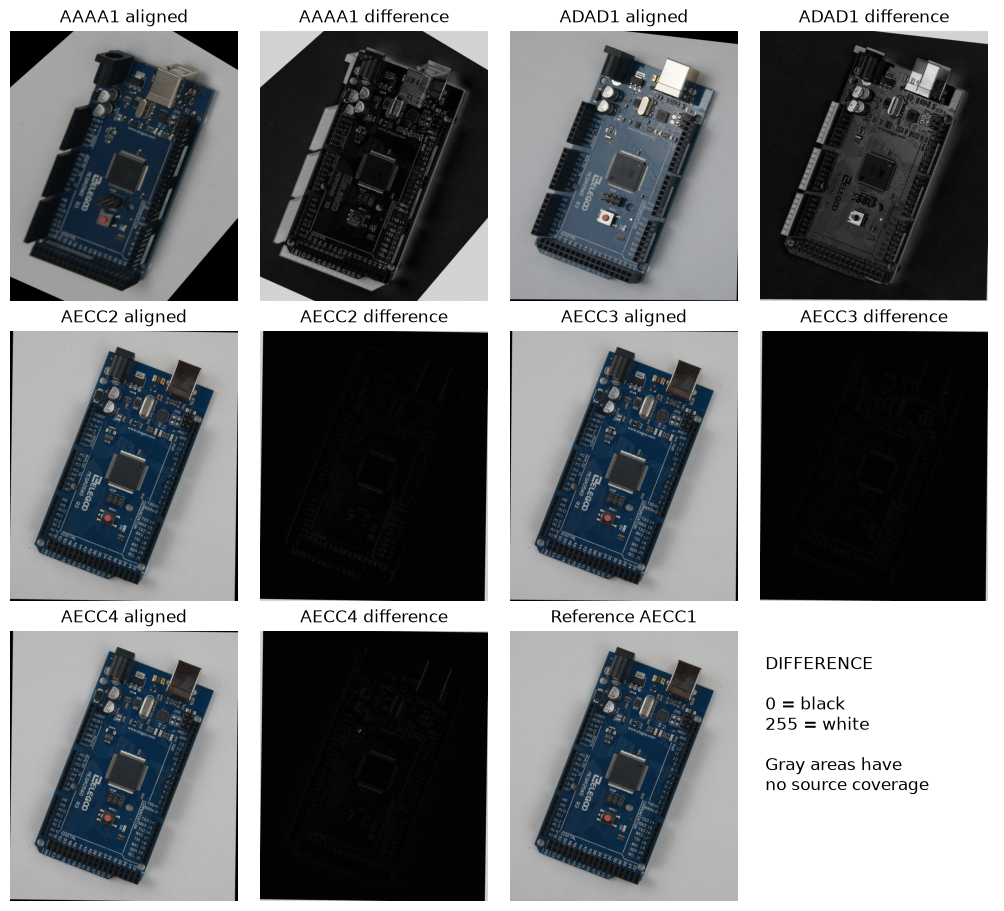

In [12]:
def warp_and_difference(image, reference, homography):
    homography = np.asarray(homography, dtype=np.float64)
    if homography.shape != (
        3,
        3,
    ) or not np.isfinite(homography).all() or np.linalg.matrix_rank(homography) != 3:
        raise ValueError('A finite homography of rank three is required')
    size = (reference.shape[1], reference.shape[0])
    warped = cv.warpPerspective(image, homography, size, flags=cv.INTER_LINEAR)
    support = cv.warpPerspective(
        np.ones(image.shape[:2], np.float32),
        homography,
        size,
        flags=cv.INTER_LINEAR,
    )
    valid = support >= 1 - 1e-06
    if not valid.any():
        raise ValueError('The warped image has no valid overlap with the reference')
    warped_gray = cv.cvtColor(warped, cv.COLOR_BGR2GRAY)
    reference_gray = cv.cvtColor(reference, cv.COLOR_BGR2GRAY)
    difference = cv.absdiff(warped_gray, reference_gray)
    difference[~valid] = 0
    return (warped, difference, valid)

fig, axes = plt.subplots(3, 4, figsize=(10, 9), layout='constrained')
print('Image       Valid coverage (%)    Mean gray difference')
for index, name in enumerate(pcb_names):
    result = pcb_results[name]
    aligned, difference, valid = warp_and_difference(result['image'], reference, result['record']['homography'])
    result.update({'aligned': aligned, 'difference': difference, 'valid': valid})
    print(f"{Path(name).stem:<10} {100 * valid.mean():18.2f} {difference[valid].mean():23.2f}")
    first, second = axes.flat[2 * index], axes.flat[2 * index + 1]
    first.imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
    first.set_title(f'{Path(name).stem} aligned')
    view = np.ma.array(difference, mask=~valid)
    colormap = plt.get_cmap('gray').with_extremes(bad='lightgray')
    second.imshow(view, cmap=colormap, vmin=0, vmax=255)
    second.set_title(f'{Path(name).stem} difference')
axes.flat[10].imshow(cv.cvtColor(reference, cv.COLOR_BGR2RGB))
axes.flat[10].set_title('Reference AECC1')
axes.flat[11].text(0.05, 0.65, 'DIFFERENCE\n\n0 = black\n255 = white\n\nGray areas have\nno source coverage',
                   fontsize=12, va='center', transform=axes.flat[11].transAxes)
for axis in axes.flat:
    axis.axis('off')
plt.show()


**RESULTS AND DISCUSSION**

AECC2, AECC3 and AECC4 have mean gray differences around 3, while AAAA1 and ADAD1 are about 28 and 31. This agrees with the darker difference images for the AECC views and the stronger changes around component edges in the other two views

The USB Type B port, capacitors and reset button stand above the board. A homography aligns one plane, so these raised parts can still shift between views. This is parallax. Reflections, shadows, lighting changes and small alignment errors also contribute to the differences

### CONCLUSION

The LoG detector found the larger sunflower centres, and RANSAC recovered the line and circle from the mixed point set. Homographies gave useful compositing and PCB alignment results, while raised components and lighting changes still affected the image differences